In [1]:
from search_utils.utils import define_env
from search_utils.SearchAlgorithms import LowestSearch_Poda, HighestSearch_Poda
from adabyron_environment.AdaByronDEMO_v2 import AdaByronDEMO
from adabyron_environment.mercadoSecundario_v2 import MercadoSecundario
from adabyron_environment.agents.storageBattery_v2 import StorageBattery
from adabyron_environment.agents.storageBattery_mercado_secundario import StorageBatteryMS
from adabyron_environment.agents.airConditioning_v2 import Airconditioning
from queue import PriorityQueue
from itertools import permutations
from datetime import date
from search_utils.message_broker_controller import MessageBrokerController
import random
import itertools
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import influxdb_client, os, time
from influxdb_client import InfluxDBClient, Point, WritePrecision
from influxdb_client.client.write_api import SYNCHRONOUS

In [2]:
mercadoDiario   = pd.read_csv('test_data/mercadoDiario.csv', sep=';')
mercadoDiario['value'] = mercadoDiario['value']/1000
mercadoDiario   = list(mercadoDiario['value'])

In [3]:
# Reading the data from mqtt broker
mqtt_service = MessageBrokerController()

# Prediction curve values
#topic_consumption_curve = os.environ.get('TOPIC_CONSUMPTION_CURVE')
#topic_generation_curve = os.environ.get('TOPIC_GENERATION_CURVE')

#read_consumption = mqtt_service.read_from_topic(topic_consumption_curve)
#read_generation = mqtt_service.read_from_topic(topic_generation_curve)





topic_adabyron_data = "gedera/data/adabyron"

#Battery
read_data = mqtt_service.read_from_topic(topic_adabyron_data)
battery_current_soc = None

read_data = json.loads(read_data.payload)

for data in read_data["Data"]:
    if data['Name'] == 'AdaByronBatterySoC':
        battery_current_soc = data['Value']
        

In [5]:
INFLUX_TOKEN="<INFLUX_TOKEN>"
INFLUX_ORG = "<INFLUX_ORG>"
INFLUX_URL = "<INFLUX_URL>"

with InfluxDBClient(url=INFLUX_URL, token=INFLUX_TOKEN, org=INFLUX_ORG, timeout=900) as client:
    query = 'from(bucket: "data") \
                |> range(start: 2010-04-30T21:00:00.000Z) \
                |> filter(fn: (r) => r["_measurement"] == "uma_loxone_weather_1") \
                |> filter(fn: (r) => r["_field"] == "val_temperature") \
                |> keep(columns: ["_time", "_value"]) \
                |> last()'
    tables = client.query_api().query(query, org=INFLUX_ORG)
    
    for table in tables:
            for record in table.records:
                temperatura = record["_value"]

temperatura = float(temperatura)

### Servicio de flexibilidad

In [6]:
generated = [random.random() for i in range(0, 24)]
consump = [i+30 for i in generated]

servicio_flexibilidad = AdaByronDEMO(agents = [Airconditioning("aire1"), StorageBattery("bateria1", capacity = 80, current_soc = battery_current_soc)], 
                 consumption_curve = consump, 
                 generated_energy = generated, 
                 energy_price = mercadoDiario, 
                 season = 0, 
                 temp_range = [21, 25], 
                 outside_temp = temperatura, 
                 expected_saving_percentage = 5)
initial = servicio_flexibilidad.reset()

resultado_servicio_flexibilidad, mejor_solucion = LowestSearch_Poda(servicio_flexibilidad.reset(), servicio_flexibilidad, 7)

0.95
1
Found new best solution with price 0.0022993324
Found new best solution with price 0.0020841004000000003
Found new best solution with price 0.0020656000000000003
Found new best solution with price 0.0020606680000000003
Found new best solution with price 0.0020527360000000003
Found new best solution with price 0.0020478040000000003


KeyboardInterrupt: 

In [ ]:
array_temp = []
array_price = []
array_consumption = []

for solutions in resultado_servicio_flexibilidad:
    actual = solutions
    
    tmp = []
    pr = []
    con = []
    
    while(actual.day_step > -1):
        con.append(actual.consumption)
        pr.append(actual.cumulative_price)
        tmp.append(actual.specific["actual_temp"])
        
        actual=actual.father
        
    array_consumption.append(con)
    array_price.append(pr)
    array_temp.append(tmp)
    

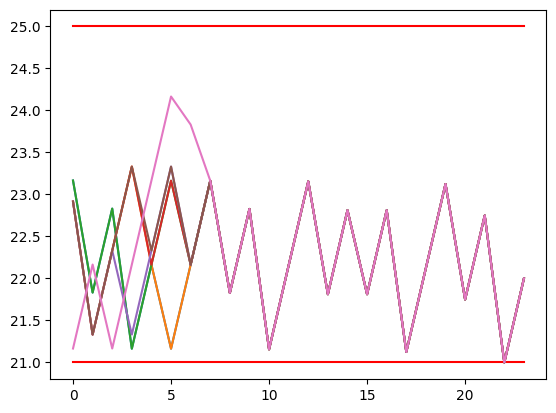

In [ ]:
for r in array_temp:
    r.reverse()

tempH = [25 for i in range(0, 24)]
tempL = [21 for i in range(0, 24)]

plt.plot(tempH, color='red')
plt.plot(tempL, color = 'red')

for a in array_temp:
    plt.plot(a)

#plt.savefig("images\\Flexibilidad\\LS_Poda\\Flexibilidad_Temp_{}.png".format(date.today()))

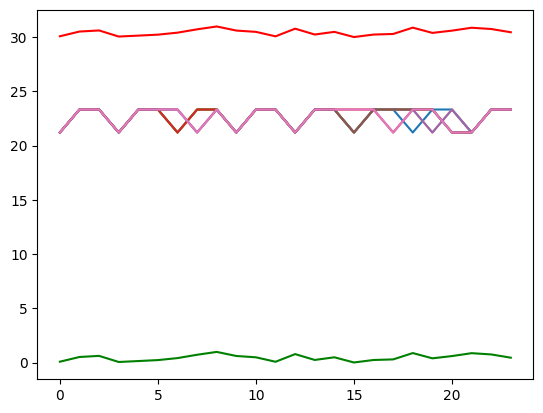

In [ ]:
for r in array_consumption:
    r.reverse()


plt.plot(generated, color='green')
plt.plot(consump, color = 'red')

for a in array_consumption:
    plt.plot(a)

plt.savefig("images\\Flexibilidad\\LS_Poda\\Flexibilidad_Consumo_{}.png".format(date.today()))

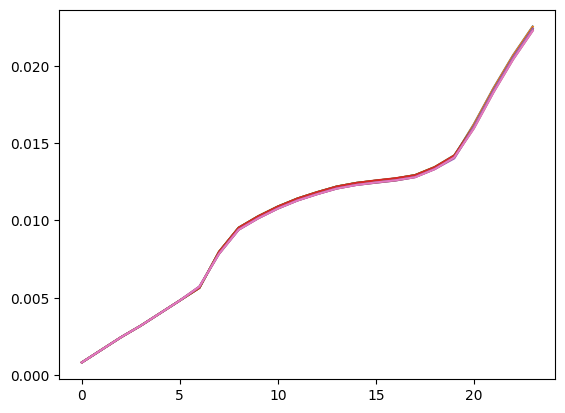

In [ ]:
for r in array_price:
    r.reverse()
for a in array_price:
    plt.plot(a)
plt.savefig("images\\Flexibilidad\\LS_Poda\\Flexibilidad_Precios_{}.png".format(date.today()))

In [ ]:
import datetime

#Get a 00:00:00 timestamp
today = datetime.datetime.now()
today = today.replace(day = today.day+1, hour=0, minute=0, second=0, microsecond=0)

print(today)


2024-11-27 00:00:00
